# Hussein Jawad

**CSCI E-89 Deep Learning – Homework 6**

# Problem 1

**Problem statement.** Plots of training data on slides 24 and 28 are actually from another
example and not from Géron's chapter 18 notebook. Use the following code to generate a new set
of 3D data `X_train`:

```python
import numpy as np
np.random.seed(4)
def generate_3d_data(m, w1=0.1, w2=0.3, noise=0.1):
    angles = np.random.rand(m) * 3 * np.pi / 2 - 0.5
    data = np.empty((m, 3))
    data[:, 0] = np.cos(angles) + np.sin(angles)/2 + noise * np.random.randn(m) / 2
    data[:, 1] = np.sin(angles) * 0.7 + noise * np.random.randn(m) / 2
    data[:, 2] = data[:, 0] * w1 + data[:, 1] * w2 + noise * np.random.randn(m)
    return data

X_train = generate_3d_data(60)
X_train = X_train - X_train.mean(axis=0, keepdims=0)
```

Create validation data, train the autoencoder with code given on slide 25 and plot resulting 2D
`codings`.

**Approach.** We create validation data `X_valid` with the same function, train the linear
autoencoder from slide 25 (`encoder = nn.Linear(3, 2)`, `decoder = nn.Linear(2, 3)`) on the new
`X_train` while tracking the validation loss, and reproduce the two plots from the slides using
this data:

* **slide 24:** the 3D training data, drawn with a 3D `scatter()` plot, and
* **slide 28:** the 2D `codings` output by the encoder (first hidden layer).

The code draws on Lab 6, Géron's chapter 18 notebook, and the lecture slides, using them only
where they keep the code simple.

# Google Colab setup

Mount Google Drive so that the saved figures persist between Colab sessions.
(When the notebook is run outside Colab, the current folder is used instead.)

In [1]:
# %pip install torch matplotlib  # Uncomment once if the packages are missing.

import sys                                              # Access to the list of loaded modules.
from pathlib import Path                                # Path builds file paths that work on any OS.

IS_COLAB = "google.colab" in sys.modules                # True when running inside Google Colab.
if IS_COLAB:                                            # Only Colab can mount Google Drive.
    from google.colab import drive                      # Colab tool to connect your Google Drive.
    drive.mount('/content/drive')                       # Mount Google Drive (asks for permission the first time).
    PROJECT_DIR = Path('/content/drive/MyDrive/CSCI-E-89-1-Deep-Learning/HW06')  # Project folder in Google Drive; saved figures persist between Colab sessions.
else:                                                   # Running locally (e.g., Jupyter on a laptop).
    PROJECT_DIR = Path.cwd()                            # Use the notebook's current folder.
PROJECT_DIR.mkdir(parents=True, exist_ok=True)          # Create the folder; no error if it already exists.
print('Project folder:', PROJECT_DIR)                   # Show where outputs will be saved.

Mounted at /content/drive
Project folder: /content/drive/MyDrive/CSCI-E-89-1-Deep-Learning/HW06


# Setup

In [2]:
import numpy as np                                      # NumPy: arrays for generating and plotting the data.
import torch                                            # PyTorch: tensors, GPU support, and automatic gradient computation.
from torch import nn                                    # Neural network layers and loss functions.
from torch.utils.data import DataLoader, TensorDataset  # Split the data into shuffled mini-batches.
import matplotlib.pyplot as plt                         # Plotting library.

device = "cuda" if torch.cuda.is_available() else "cpu" # Use the Colab GPU if one is available.
print("PyTorch:", torch.__version__, "| device:", device)  # Show the PyTorch version and device.

IMAGES_DIR = PROJECT_DIR / "images"                     # Folder for the saved figures.
IMAGES_DIR.mkdir(exist_ok=True)                         # Create it; no error if it already exists.

PyTorch: 2.11.0+cu130 | device: cuda


## Build the 3D dataset (code given in Problem 1)

In [3]:
np.random.seed(4)                                       # Fix the random seed so every run generates the same dataset.

def generate_3d_data(m, w1=0.1, w2=0.3, noise=0.1):     # m = number of points; w1, w2 = slopes of the plane for x3; noise = noise level.
    angles = np.random.rand(m) * 3 * np.pi / 2 - 0.5    # One random angle per point, from -0.5 to 3π/2 - 0.5 radians (3/4 of a circle).
    data = np.empty((m, 3))                             # Empty table: m rows (points) x 3 columns (x1, x2, x3).
    data[:, 0] = np.cos(angles) + np.sin(angles)/2 + noise * np.random.randn(m) / 2  # x1: position along a tilted arc, plus a little random noise.
    data[:, 1] = np.sin(angles) * 0.7 + noise * np.random.randn(m) / 2  # x2: squeezed by 0.7 so the arc is an oval, plus a little random noise.
    data[:, 2] = data[:, 0] * w1 + data[:, 1] * w2 + noise * np.random.randn(m)  # x3 = w1*x1 + w2*x2 (a tilted plane), plus noise that moves points slightly off it.
    return data                                         # The m x 3 dataset.

X_train = generate_3d_data(60)                          # 60 training points (a 60 x 3 array).
X_train = X_train - X_train.mean(axis=0, keepdims=0)    # Subtract each column's mean so the data is centered at the origin (PCA assumes centered data).
print(X_train.shape)                                    # (60, 3): 60 points with 3 coordinates each.

(60, 3)


## Create validation data

We draw 20 more instances from the same distribution (about a third of the training set size)
and center them the same way. They are generated *after* `X_train`, so `X_train` is unchanged.
The validation data is never used to update the weights; it only shows how well the autoencoder
reconstructs data it has not seen.

In [4]:
X_valid = generate_3d_data(20)                         # 20 validation instances, same distribution.
X_valid = X_valid - X_valid.mean(axis=0, keepdims=0)    # Center them the same way as X_train.
print(X_valid.shape)                                    # (20, 3).

(20, 3)


## Visualize the data (slide 24)

A 3D scatter plot of the 60 training points:

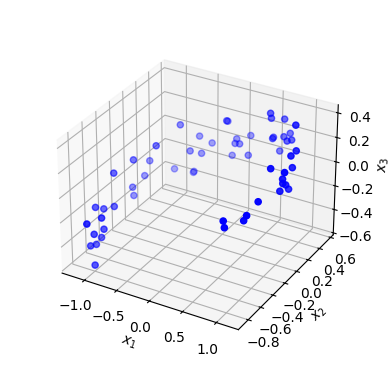

In [5]:
fig = plt.figure()                                      # New figure.
ax = fig.add_subplot(111, projection="3d")              # 3D axes; 111 = 1 row, 1 column, plot number 1.
ax.scatter(X_train[:, 0], X_train[:, 1], X_train[:, 2], c="b", marker="o")  # One blue dot per point.
ax.set_xlabel("$x_1$")                                  # First coordinate.
ax.set_ylabel("$x_2$")                                  # Second coordinate.
ax.set_zlabel("$x_3$")                                  # Third coordinate (near the plane 0.1*x1 + 0.3*x2).
ax.set_box_aspect(None, zoom=0.85)                      # Shrink the 3D box slightly so the x3 label isn't cut off.
plt.savefig(IMAGES_DIR / "problem1_3d_training_data.png", dpi=300)  # Save the figure (to Drive in Colab).
plt.show()                                              # Display the figure.

## Build the autoencoder (slide 25)

The encoder and the decoder are each a single `nn.Linear` layer, chained with `nn.Sequential`.
The model has 3 inputs, a 2D coding layer, and 3 outputs. To perform PCA we use **no activation
function** (all neurons are linear) and the **MSE** loss.

In [6]:
torch.manual_seed(42)                                   # Reproducible weight initialization.
encoder = nn.Linear(3, 2)                               # Encoder: 3D inputs -> 2D codings.
decoder = nn.Linear(2, 3)                               # Decoder: 2D codings -> 3D reconstructions.
autoencoder = nn.Sequential(encoder, decoder).to(device)  # Chain encoder and decoder; move to the GPU.

## Train the autoencoder

The same data, `X_train`, is both the input and the target: the autoencoder learns to
reconstruct its own input through the 2D bottleneck.

We use the NAdam optimizer (as in Géron's notebook) with lr=0.02, and train for 100 epochs in
mini-batches of 32. After each epoch we also compute the loss on the validation data. The loss levels off after about 40 epochs; the extra epochs are a safety
margin.

In [7]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)  # NumPy array -> PyTorch tensor (float32).
X_valid_t = torch.tensor(X_valid, dtype=torch.float32).to(device)  # Validation tensor, on the GPU.
train_loader = DataLoader(TensorDataset(X_train_t), batch_size=32, shuffle=True)  # Shuffled mini-batches of 32.

optimizer = torch.optim.NAdam(autoencoder.parameters(), lr=0.02)  # Optimizer that updates the weights.
loss_fn = nn.MSELoss()                                  # Reconstruction error: mean squared error.
n_epochs = 100                                          # Number of passes over the training data.
losses, valid_losses = [], []                           # Training and validation loss per epoch.

for epoch in range(n_epochs):                           # Loop over the epochs.
    total_loss = 0.0                                    # Sum of the losses in this epoch.
    for (X_batch,) in train_loader:                     # Loop over the mini-batches; (X_batch,) unpacks the 1-item group the DataLoader gives (data only, no labels).
        X_batch = X_batch.to(device)                    # Move the batch to the GPU.
        X_rec = autoencoder(X_batch)                    # Forward pass: reconstruct the inputs.
        loss = loss_fn(X_rec, X_batch)                  # Compare reconstructions with the inputs.
        optimizer.zero_grad()                           # Reset the gradients from the previous step.
        loss.backward()                                 # Backpropagation: compute the gradients.
        optimizer.step()                                # Update the weights.
        total_loss += loss.item() * len(X_batch)        # loss is the batch's average, so x batch size = batch total; .item() turns it into a plain number.
    losses.append(total_loss / len(X_train_t))          # Mean training loss over the epoch.
    with torch.no_grad():                               # Validation only measures: no gradients, no updates.
        valid_loss = loss_fn(autoencoder(X_valid_t), X_valid_t)  # Reconstruction error on the validation data.
    valid_losses.append(valid_loss.item())              # Record it.
    if (epoch + 1) % 10 == 0:                           # Print every 10 epochs.
        print(f"Epoch {epoch + 1}/{n_epochs}: loss={losses[-1]:.4f}, valid_loss={valid_losses[-1]:.4f}")  # Show the training and validation loss.

Epoch 10/100: loss=0.0760, valid_loss=0.0560
Epoch 20/100: loss=0.0428, valid_loss=0.0378
Epoch 30/100: loss=0.0118, valid_loss=0.0099
Epoch 40/100: loss=0.0036, valid_loss=0.0048
Epoch 50/100: loss=0.0035, valid_loss=0.0048
Epoch 60/100: loss=0.0035, valid_loss=0.0049
Epoch 70/100: loss=0.0034, valid_loss=0.0047
Epoch 80/100: loss=0.0035, valid_loss=0.0046
Epoch 90/100: loss=0.0034, valid_loss=0.0047
Epoch 100/100: loss=0.0036, valid_loss=0.0049


Learning curves (log scale): both losses drop together and level off close to each other after about 40 epochs, so the model is not overfitting.

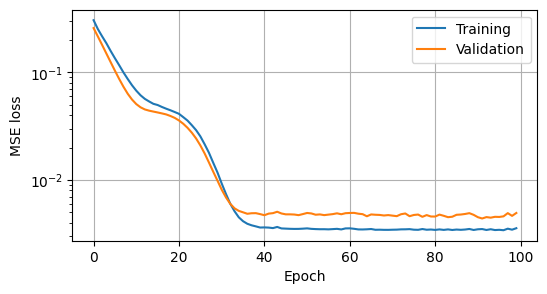

In [8]:
plt.figure(figsize=(6, 3))                              # New figure.
plt.semilogy(losses, label="Training")                  # Training loss per epoch, log scale.
plt.semilogy(valid_losses, label="Validation")          # Validation loss per epoch, log scale.
plt.legend()                                            # Show which curve is which.
plt.xlabel("Epoch")                                     # x-axis label.
plt.ylabel("MSE loss")                                  # y-axis label.
plt.grid(True)                                          # Add a grid.
plt.show()                                              # Display the figure.

## `codings`, outputs of the first hidden layer (slide 28)

No `Linear` layer is followed by a non-linear unit. We trained with 60 vectors of dimension 3,
so the encoder (first hidden layer) produces 60 vectors of dimension 2 (`codings`):

In [9]:
with torch.no_grad():                                   # Just using the model: no gradients needed.
    codings = encoder(X_train_t.to(device))             # Run only the encoder: 3D -> 2D.
codings = codings.cpu().numpy()                         # Back to the CPU as a NumPy array for plotting.
print(codings.shape)                                    # (60, 2): 60 vectors of dimension 2.

(60, 2)


Plot the 2D codings:

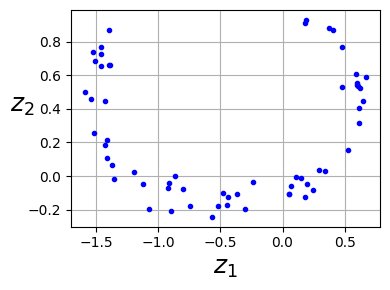

In [10]:
plt.figure(figsize=(4, 3))                              # New figure.
plt.plot(codings[:, 0], codings[:, 1], "b.")            # One blue dot per coding.
plt.xlabel("$z_1$", fontsize=18)                        # First coding dimension.
plt.ylabel("$z_2$", fontsize=18, rotation=0)            # Second coding dimension.
plt.grid(True)                                          # Add a grid.
plt.tight_layout()                                      # Avoid cutting off the axis labels.
plt.savefig(IMAGES_DIR / "problem1_codings_2d.png", dpi=300)  # Save the figure (to Drive in Colab).
plt.show()                                              # Display the figure.

**Observation:** the 3D training data lies close to the plane $x_3 \approx 0.1x_1 + 0.3x_2$, curved
into an arc. The 2D codings keep that arc shape and drop only the low-variance direction (mostly
the noise off the plane). Like PCA, the linear autoencoder found the best 2D plane to project
the data onto: the plane that keeps the largest variance. Its coding
axes $z_1, z_2$ need not be the principal components themselves (they can be rotated, scaled
or skewed within that plane), which is why the arc may look rotated or stretched compared with
a PCA plot.

# Problem 2

**Problem statement.** Train a deep autoencoder with the architecture presented on slide 33 and
train it on MNIST data (images of handwritten digits). Present the original images of the first
5 elements of that data set and their reconstructed images.

**Approach.** We load MNIST with `torchvision` (as in HW04), build the stacked autoencoder from
slide 33, train it to reconstruct the images, and then show the first 5 training images next to
their reconstructions. The training loop is the same one used in Problem 1.

## Load the MNIST images

MNIST has 60,000 training images of handwritten digits. Each image is 28 x 28 pixels, with
values from 0 (black) to 255 (white). As in HW04, we divide the pixels by 255 so they are between
0 and 1. This also matches the decoder's last layer (`nn.Sigmoid()`), which can only output values
between 0 and 1.

In [ ]:
from torchvision import datasets                        # torchvision has ready-made image datasets, including MNIST.

mnist_train = datasets.MNIST(root="./data", train=True, download=True)  # 60,000 training images (downloads them the first time).
train_images = mnist_train.data.float().unsqueeze(1) / 255.0  # .data = raw pixels; .float() makes them decimals; / 255.0 scales 0-255 to 0-1; unsqueeze(1) adds the 1 color channel: (60000, 1, 28, 28).

## Build the stacked autoencoder (slide 33)

The encoder squeezes each 28 x 28 image (784 pixels) down to just 32 numbers (the codings), and
the decoder rebuilds the 784 pixels from those 32 numbers:

784 pixels → 128 → **32 (codings)** → 128 → 784 pixels

There are 3 hidden layers (128, 32, 128) and 1 output layer (784), so this is a deep (stacked)
autoencoder. Because the network has only 32 numbers to describe each image, it must learn the
most important features of the digits instead of just copying the pixels.

In [ ]:
torch.manual_seed(42)                                   # Same starting weights every run (reproducible results).

stacked_encoder = nn.Sequential(                        # Encoder: image -> 32 codings.
    nn.Flatten(),                                       # Turn each 1 x 28 x 28 image into a flat list of 784 pixels.
    nn.Linear(1 * 28 * 28, 128), nn.ReLU(),             # Hidden layer 1: 784 -> 128 numbers; ReLU sets negatives to 0.
    nn.Linear(128, 32), nn.ReLU(),                      # Hidden layer 2: 128 -> 32 numbers. These 32 numbers are the codings.
)
stacked_decoder = nn.Sequential(                        # Decoder: 32 codings -> image.
    nn.Linear(32, 128), nn.ReLU(),                      # Hidden layer 3: 32 -> 128 numbers.
    nn.Linear(128, 1 * 28 * 28), nn.Sigmoid(),          # Output layer: 128 -> 784 pixels; Sigmoid keeps each pixel between 0 and 1.
    nn.Unflatten(dim=1, unflattened_size=(1, 28, 28))   # Turn the 784 pixels back into a 1 x 28 x 28 image.
)
stacked_ae = nn.Sequential(stacked_encoder, stacked_decoder).to(device)  # Full autoencoder: encoder then decoder, on the GPU.

## Train the autoencoder

The loop is the same as in Problem 1: each image is both the input and the target, and the loss
(MSE) measures how different the rebuilt image is from the original, pixel by pixel.

We use the NAdam optimizer as in Géron's notebook, but with lr=0.001 instead of his lr=0.01:
his `train()` function lowers the learning rate automatically during training, and our simple
loop does not. In our tests, lr=0.001 reached a lower loss after 10 epochs (about 0.010 vs. 0.016).

In [ ]:
mnist_loader = DataLoader(TensorDataset(train_images), batch_size=64, shuffle=True)  # Serve the training images in random batches of 64.

stacked_optimizer = torch.optim.NAdam(stacked_ae.parameters(), lr=0.001)  # Optimizer that updates the weights.
loss_fn = nn.MSELoss()                                  # Mean squared error between rebuilt and original pixels.
n_epochs = 10                                           # Number of passes over all 60,000 training images.

for epoch in range(n_epochs):                           # Loop over the epochs.
    total_loss = 0.0                                    # Sum of the losses in this epoch.
    for (X_batch,) in mnist_loader:                     # Loop over the batches of 64 images; (X_batch,) unpacks the 1-item group the DataLoader gives (images only, no labels).
        X_batch = X_batch.to(device)                    # Move the batch to the GPU.
        X_rec = stacked_ae(X_batch)                     # Forward pass: rebuild the images.
        loss = loss_fn(X_rec, X_batch)                  # How different are the rebuilt images from the originals?
        stacked_optimizer.zero_grad()                   # Reset the gradients from the previous step.
        loss.backward()                                 # Backpropagation: compute the gradients.
        stacked_optimizer.step()                        # Update the weights to reduce the loss.
        total_loss += loss.item() * len(X_batch)        # loss is the batch's average, so x batch size = batch total; .item() turns it into a plain number.
    print(f"Epoch {epoch + 1}/{n_epochs}: loss={total_loss / len(train_images):.4f}")  # Show the mean loss of this epoch.

## Original vs. reconstructed images (first 5 elements)

The top row shows the first 5 images of the MNIST training set; the bottom row shows the
autoencoder's reconstructions of the same images.

In [ ]:
first_5 = train_images[:5]                              # The first 5 images of the data set.
with torch.no_grad():                                   # Just using the trained model: no gradients needed.
    rebuilt_5 = stacked_ae(first_5.to(device)).cpu()    # Rebuild them on the GPU, then bring them back to the CPU for plotting.

fig, axes = plt.subplots(2, 5, figsize=(9, 4))          # 2 rows (original, rebuilt) x 5 columns (one per image).
for i in range(5):                                      # Loop over the 5 images.
    axes[0, i].imshow(first_5[i, 0], cmap="gray")       # Top row: original image ([i, 0] = image i, its only channel).
    axes[0, i].set_title("Original")                    # Title for the original image.
    axes[0, i].axis("off")                              # Hide the axis ticks.
    axes[1, i].imshow(rebuilt_5[i, 0], cmap="gray")     # Bottom row: the autoencoder's reconstruction.
    axes[1, i].set_title("Reconstructed")               # Title for the rebuilt image.
    axes[1, i].axis("off")                              # Hide the axis ticks.
plt.tight_layout()                                      # Avoid overlapping titles.
plt.savefig(IMAGES_DIR / "problem2_reconstructions.png", dpi=300)  # Save the figure (to Drive in Colab).
plt.show()                                              # Display the figure.

**Observation:** the reconstructions keep the overall shape of each digit, even though the
autoencoder had to rebuild all 784 pixels from only 32 numbers (about 25 times fewer). They are
blurrier than the originals: fine details of the handwriting are lost, and thin or unusual
strokes (such as the open top of the 4) come out smudged. Training longer, or using more codings
than 32, would make the reconstructions sharper.

# Problem 3

**Problem statement.** Pass 4 images from the Fashion MNIST data set to the autoencoder trained
in Problem 2 and present their reconstructed images. This is a demonstration of the anomaly
detection. Calculate the loss value that such autoencoder produces for MNIST images and the loss
values for Fashion MNIST images. Compare.

**Approach.** The autoencoder from Problem 2 only ever saw handwritten digits. Clothing images
from Fashion MNIST are "anomalies" for it: it should rebuild them poorly, so their loss should be
much higher than for digits. We load Fashion MNIST the same way as MNIST in Problem 2, show 4
Fashion images with their reconstructions, and compare the loss on MNIST and Fashion MNIST
images. For a fair comparison we use the MNIST *test* images, which the autoencoder never saw
during training (just like the Fashion MNIST images).

## Load Fashion MNIST and the MNIST test images

Fashion MNIST has the same format as MNIST (28 x 28 grayscale images, pixels 0-255), but shows
clothing instead of digits. `torchvision` loads it exactly like MNIST; only the name changes.

In [ ]:
fashion_test = datasets.FashionMNIST(root="./data", train=False, download=True)  # 10,000 Fashion MNIST test images (clothing).
mnist_test = datasets.MNIST(root="./data", train=False, download=True)  # 10,000 MNIST test images (digits the model never trained on).

fashion_images = fashion_test.data.float().unsqueeze(1) / 255.0  # Same preparation as Problem 2: raw pixels -> decimals -> 0-1, plus the color channel: (10000, 1, 28, 28).
mnist_test_images = mnist_test.data.float().unsqueeze(1) / 255.0  # Same preparation for the MNIST test images: (10000, 1, 28, 28).

## Reconstruct 4 Fashion MNIST images

We pass the first 4 Fashion MNIST images through the autoencoder trained in Problem 2 (no new
training) and show the originals (top) and the reconstructions (bottom).

In [ ]:
fashion_4 = fashion_images[:4]                          # The first 4 Fashion MNIST images.
with torch.no_grad():                                   # Just using the trained model: no gradients needed.
    fashion_rebuilt_4 = stacked_ae(fashion_4.to(device)).cpu()  # Rebuild them with the Problem 2 autoencoder; back to CPU for plotting.

fig, axes = plt.subplots(2, 4, figsize=(8, 4))          # 2 rows (original, rebuilt) x 4 columns (one per image).
for i in range(4):                                      # Loop over the 4 images.
    axes[0, i].imshow(fashion_4[i, 0], cmap="gray")     # Top row: original Fashion MNIST image.
    axes[0, i].set_title("Original")                    # Title for the original image.
    axes[0, i].axis("off")                              # Hide the axis ticks.
    axes[1, i].imshow(fashion_rebuilt_4[i, 0], cmap="gray")  # Bottom row: the autoencoder's reconstruction.
    axes[1, i].set_title("Reconstructed")               # Title for the rebuilt image.
    axes[1, i].axis("off")                              # Hide the axis ticks.
plt.tight_layout()                                      # Avoid overlapping titles.
plt.savefig(IMAGES_DIR / "problem3_fashion_reconstructions.png", dpi=300)  # Save the figure (to Drive in Colab).
plt.show()                                              # Display the figure.

## Compare the loss on MNIST and Fashion MNIST images

The loss is the same MSE used for training: the average squared difference between the original
and the rebuilt pixels. A higher loss means a worse reconstruction. We pass 4 MNIST images through
the autoencoder too, and compare the loss of each image and of each group of 4 images.

In [ ]:
mnist_4 = mnist_test_images[:4]                         # The first 4 MNIST test images (digits).
with torch.no_grad():                                   # Just using the trained model: no gradients needed.
    mnist_rebuilt_4 = stacked_ae(mnist_4.to(device)).cpu()  # Rebuild them; back to the CPU like the Fashion images.

mnist_each = ((mnist_rebuilt_4 - mnist_4) ** 2).mean(dim=(1, 2, 3))  # Squared pixel errors, averaged over each image's channel, height and width (dims 1, 2, 3): one loss per MNIST image.
fashion_each = ((fashion_rebuilt_4 - fashion_4) ** 2).mean(dim=(1, 2, 3))  # Same calculation: one loss per Fashion MNIST image.
mnist_loss = loss_fn(mnist_rebuilt_4, mnist_4).item()   # One loss value for the 4 MNIST images together; .item() turns it into a plain number.
fashion_loss = loss_fn(fashion_rebuilt_4, fashion_4).item()  # One loss value for the 4 Fashion MNIST images together; .item() turns it into a plain number.

print("Loss of each image:")                            # Heading for the per-image losses.
print("  MNIST:        ", [round(v, 4) for v in mnist_each.tolist()])    # Loss of each of the 4 digits, as a list rounded to 4 decimals.
print("  Fashion MNIST:", [round(v, 4) for v in fashion_each.tolist()])  # Loss of each of the 4 clothing images, as a list rounded to 4 decimals.
print("Loss of the 4 images together:")                 # Heading for the overall losses.
print(f"  MNIST:         {mnist_loss:.4f}")               # Loss on the 4 digits.
print(f"  Fashion MNIST: {fashion_loss:.4f}")             # Loss on the 4 clothing images.

**Comparison:** the autoencoder rebuilds the 4 digits well (loss about 0.006) but rebuilds the 4
clothing images badly (loss about 0.097, more than 10 times higher). Every Fashion MNIST image
has a much higher loss than every MNIST image. The reconstructions show
why: the autoencoder only learned how to draw digits, so a boot, a sweater and trousers come out
as smudged, digit-like blobs. This is how anomaly detection with an autoencoder works: train it
on normal data only, then flag any new image with an unusually high reconstruction loss as an
anomaly.

# Problem 4

**Problem statement.** Please generate a 2D t-SNE display for MNIST data set similar to the
display on slide 49.

**Approach.** As in Géron's notebook, we work in three steps:

1. **Compress:** the encoder trained in Problem 2 turns each of 5,000 MNIST *test* images into
   32 numbers. These are the 10,000 test images loaded in Problem 3 (`train=False`), not the
   60,000 training images from Problem 2, so the plot shows digits the autoencoder never saw
   during training.
2. **t-SNE:** squeezes those 32 numbers down to 2, giving each image an (x, y) position on the
   plot. Images that look alike end up close together.
3. **Plot:** the code from slide 48 draws one colored dot per image and shows some of the digit
   images on top, like slide 49.

## Compress the images and run t-SNE

In [ ]:
from sklearn.manifold import TSNE                       # t-SNE: squeezes many numbers per point down to 2, keeping similar points close together.

tsne_images = mnist_test_images[:5000]                  # 5,000 MNIST test images (as many as Géron uses; t-SNE gets slow with more).
tsne_labels = mnist_test.targets[:5000].numpy()         # The digit (0-9) shown in each image; used only to color the dots.
with torch.no_grad():                                   # Just using the trained model: no gradients needed.
    codings_32 = stacked_encoder(tsne_images.to(device)).cpu()  # Problem 2 encoder: each image -> 32 numbers; back to the CPU for t-SNE.
tsne = TSNE(init="pca", learning_rate="auto", random_state=42)  # Same t-SNE settings as Géron; random_state makes the result repeatable.
codings_2D = tsne.fit_transform(codings_32)             # 32 numbers per image -> 2 numbers per image (its x, y position on the plot).

## Plot the 2D t-SNE display (code from slide 48)

In [ ]:
from matplotlib.offsetbox import AnnotationBbox, OffsetImage  # Tools to draw small images inside a plot.

plt.figure(figsize=(10, 8))                             # Large figure, like slide 49.
cmap = plt.cm.tab10                                     # 10 distinct colors, one per digit.
Z = (codings_2D - codings_2D.min()) / (codings_2D.max() - codings_2D.min())  # Rescale all positions to the 0-1 range.
plt.scatter(Z[:, 0], Z[:, 1], c=tsne_labels, s=10, cmap=cmap)  # One dot per image, colored by its digit.
image_positions = np.array([[1., 1.]])                  # Where sample images have been drawn so far (starts with a dummy corner point).
for index, position in enumerate(Z):                    # Go through every dot.
    dist = ((position - image_positions) ** 2).sum(axis=1)  # Squared distance from this dot to every image drawn so far.
    if dist.min() > 0.02:                               # Draw an image here only if no other image is close by (avoids overlaps).
        image_positions = np.r_[image_positions, [position]]  # Remember this position (np.r_ adds it as a new row).
        imagebox = AnnotationBbox(                      # A small box placed on the plot, holding...
            OffsetImage(tsne_images[index, 0], cmap="binary"),  # ...this digit image (black on white, like slide 49),
            position, bboxprops={"edgecolor": cmap(tsne_labels[index]), "lw": 2})  # ...at the dot's position, with a border in the digit's color.
        plt.gca().add_artist(imagebox)                  # Add the box to the current plot.
plt.axis("off")                                         # Hide the axes, like slide 49.
plt.savefig(IMAGES_DIR / "problem4_tsne_mnist.png", dpi=300)  # Save the figure (to Drive in Colab).
plt.show()                                              # Display the figure.

**Observation:** like slide 49, images of the same digit form their own colored cluster, even
though the autoencoder never saw the labels: the 32 codings it learned are enough to tell the
digits apart. Digits that look alike sit next to each other and overlap a little (4, 7 and 9;
3, 5 and 8), while distinct digits such as 0, 1 and 6 form well-separated clusters.

# Problem 5

**Problem statement.** Implement a convolutional denoising autoencoder with dropout layer and
train it with MNIST data set. As the dropout parameter use 0.20. Produce 5 original images of
random digits and their reconstructed images. Change the dropout parameter to 0.10 and compare
new reconstructed images with the previous one. Just produce a qualitative assessment of the
change in quality of the reconstructed images if any.

**Approach.** We use the simple convolutional autoencoder from Lab 6 (ReLU instead of SELU, as in
Problem 2) and, as on slide 69, put a `Dropout` layer on the encoder's input. During training,
dropout randomly turns off a fraction of the input pixels (20% or 10%), so the autoencoder must
rebuild the full digit from a damaged copy: that is what makes it a *denoising* autoencoder.
Dropout is only active during training; when we later show the reconstructions, the model sees
the clean images. We train the same model twice (dropout 0.20 and 0.10) on the 60,000 MNIST
training images from Problem 2, then compare both reconstructions of the same 5 random digits.

## Build and train the convolutional denoising autoencoder

The model shrinks each 1 x 28 x 28 image to 64 small 3 x 3 feature maps and then rebuilds it:

1 x 28 x 28 → 16 x 14 x 14 → 32 x 7 x 7 → **64 x 3 x 3** → 32 x 7 x 7 → 16 x 14 x 14 → 1 x 28 x 28

Because we train it twice with a different dropout rate, the build and training steps are in one
function. The training loop is the same as in Problem 2 (NAdam, lr=0.001, MSE loss, 10 epochs,
batches of 64 from `mnist_loader`).

In [ ]:
def train_conv_dae(dropout_rate):                       # Builds and trains one model; dropout_rate = fraction of pixels turned off.
    torch.manual_seed(42)                               # Same starting weights for both dropout rates (fair comparison).
    model = nn.Sequential(                              # Encoder followed by decoder.
        nn.Dropout(dropout_rate),                       # Noise: randomly sets this fraction of input pixels to 0 (training only).
        nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(),   # 16 filters of 3 x 3 scan the image: 1 x 28 x 28 -> 16 x 28 x 28.
        nn.MaxPool2d(2),                                # Keep the max of each 2 x 2 block: -> 16 x 14 x 14.
        nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),  # 32 filters: -> 32 x 14 x 14.
        nn.MaxPool2d(2),                                # Halve the size: -> 32 x 7 x 7.
        nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),  # 64 filters: -> 64 x 7 x 7.
        nn.MaxPool2d(2),                                # Halve the size: -> 64 x 3 x 3 (the compressed codings).
        nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2), nn.ReLU(),  # Decoder: upscale -> 32 x 7 x 7.
        nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # Upscale -> 16 x 14 x 14.
        nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1), nn.Sigmoid(),  # Upscale -> 1 x 28 x 28; pixels 0-1.
    ).to(device)                                        # Move the model to the GPU.
    optimizer = torch.optim.NAdam(model.parameters(), lr=0.001)  # Optimizer that updates the weights.

    for epoch in range(10):                             # 10 passes over the 60,000 training images.
        total_loss = 0.0                                # Sum of the losses in this epoch.
        for (X_batch,) in mnist_loader:                 # Batches of 64 images from Problem 2; (X_batch,) unpacks the 1-item group.
            X_batch = X_batch.to(device)                # Move the batch to the GPU.
            X_rec = model(X_batch)                      # Dropout damages the input, then the model rebuilds it.
            loss = loss_fn(X_rec, X_batch)              # Compare the rebuilt images with the clean originals.
            optimizer.zero_grad()                       # Reset the gradients from the previous step.
            loss.backward()                             # Backpropagation: compute the gradients.
            optimizer.step()                            # Update the weights to reduce the loss.
            total_loss += loss.item() * len(X_batch)    # loss is the batch's average, so x batch size = batch total.
        print(f"Dropout {dropout_rate:.2f} - Epoch {epoch + 1}/10: loss={total_loss / len(train_images):.4f}")  # Show progress.

    model.eval()                                        # Evaluation mode: turns dropout off, so later inputs stay clean.
    return model                                        # Return the trained model.

dae_20 = train_conv_dae(0.20)                           # Train with dropout 0.20.
dae_10 = train_conv_dae(0.10)                           # Train again with dropout 0.10.

## Reconstruct 5 random digits with both models

We pick 5 random MNIST test images (digits neither model trained on) and show the originals
(top row), the reconstructions with dropout 0.20 (middle row) and with dropout 0.10 (bottom row).

In [ ]:
torch.manual_seed(42)                                   # Same "random" digits every run.
random_index = torch.randint(0, len(mnist_test_images), (5,))  # 5 random positions among the 10,000 test images (from Problem 3).
originals = mnist_test_images[random_index]             # The 5 random digit images.
with torch.no_grad():                                   # Just using the trained models: no gradients needed.
    rebuilt_20 = dae_20(originals.to(device)).cpu()     # Reconstructions by the dropout-0.20 model; back to the CPU for plotting.
    rebuilt_10 = dae_10(originals.to(device)).cpu()     # Reconstructions by the dropout-0.10 model.

rows = [(originals, "Original"), (rebuilt_20, "Dropout 0.20"), (rebuilt_10, "Dropout 0.10")]  # (images, title) for each row.
fig, axes = plt.subplots(3, 5, figsize=(9, 6))          # 3 rows x 5 columns (one per digit).
for row, (images, title) in enumerate(rows):            # Loop over the 3 rows.
    for i in range(5):                                  # Loop over the 5 digits.
        axes[row, i].imshow(images[i, 0], cmap="gray")  # Draw image i ([i, 0] = image i, its only channel).
        axes[row, i].set_title(title)                   # Title says which row this is.
        axes[row, i].axis("off")                        # Hide the axis ticks.
plt.tight_layout()                                      # Avoid overlapping titles.
plt.savefig(IMAGES_DIR / "problem5_dropout_comparison.png", dpi=300)  # Save the figure (to Drive in Colab).
plt.show()                                              # Display the figure.

**Qualitative assessment:** _TO BE WRITTEN after running the notebook: compare the middle row
(dropout 0.20) with the bottom row (dropout 0.10) for sharpness, stroke thickness and smudges._